In [3]:
import sys
print(sys.executable)

c:\Users\Esila Nur Demirci\Downloads\.venv\Scripts\python.exe


In [4]:
%pip install matplotlib seaborn ipykernel

  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------ --------------------------- 0.8/2.5 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 9.7 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp313-cp313-win_amd6


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
project_dir = Path.cwd()
if not (project_dir / "data" / "power_plant.csv").exists():
    project_dir = project_dir.parent

data_path = project_dir / "data" / "power_plant.csv"
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [6]:

print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values:")
display(df.isnull().sum().to_frame("missing_count"))

print("Duplicate rows:", df.duplicated().sum())

print("Descriptive statistics:")
display(df.describe().T)


Data types:


,dtype
AT,float64
V,float64
AP,float64
RH,float64
PE,float64


Missing values:


,missing_count
AT,0
V,0
AP,0
RH,0
PE,0


Duplicate rows: 41
Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


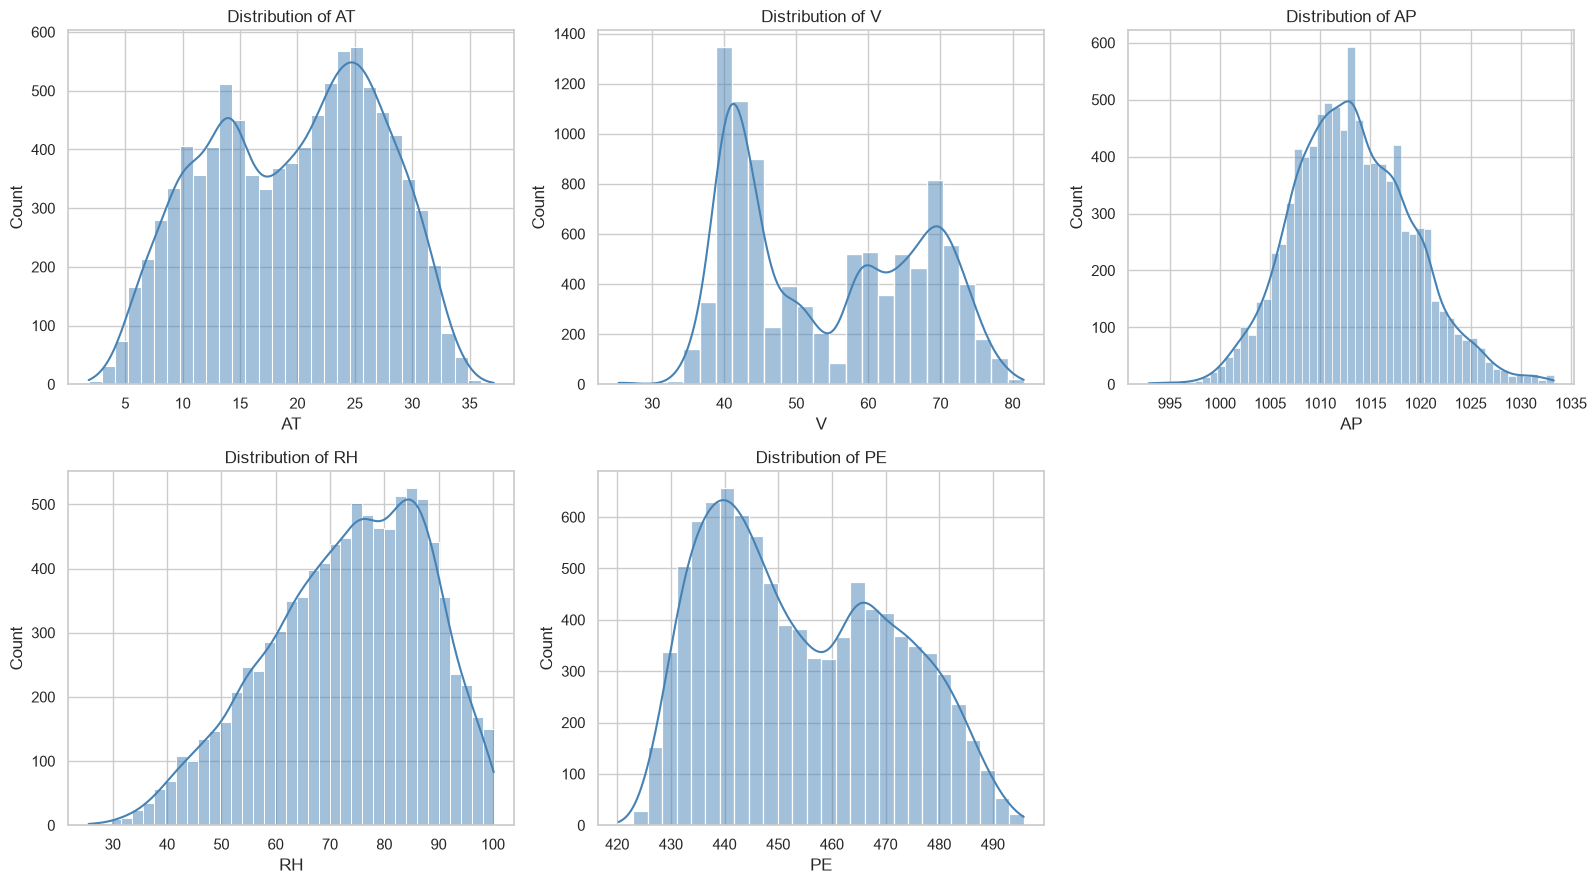

In [7]:

features = ["AT", "V", "AP", "RH"]
target = "PE"

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(features + [target]):
    sns.histplot(
        df[col],
        kde=True,
        ax=axes[i],
        color="steelblue"
    )
    axes[i].set_title(f"Distribution of {col}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()


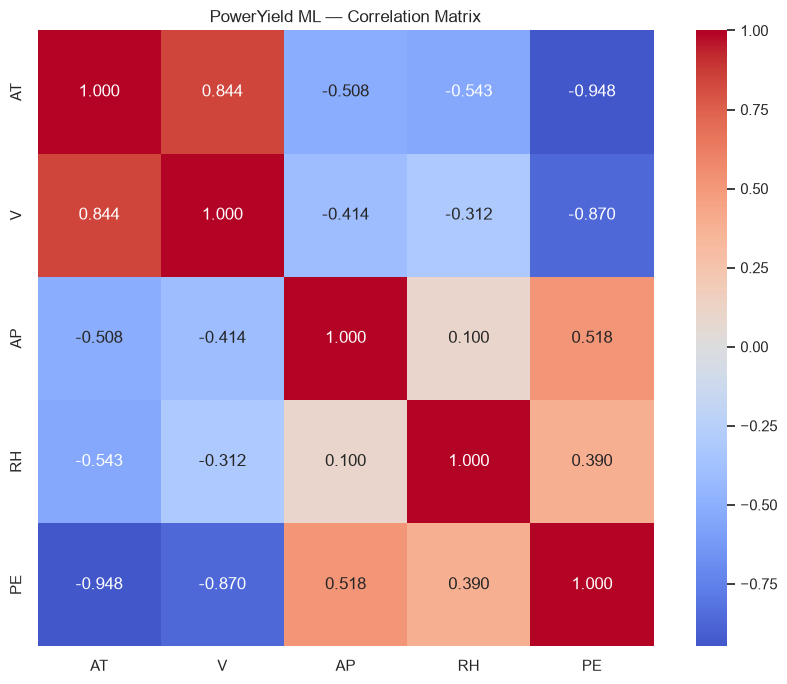

Correlation with Power Output (PE):


PE    1.000000
AP    0.518429
RH    0.389794
V    -0.869780
AT   -0.948128
Name: PE, dtype: float64

In [8]:

corr = df.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("PowerYield ML — Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with Power Output (PE):")
display(corr["PE"].sort_values(ascending=False))


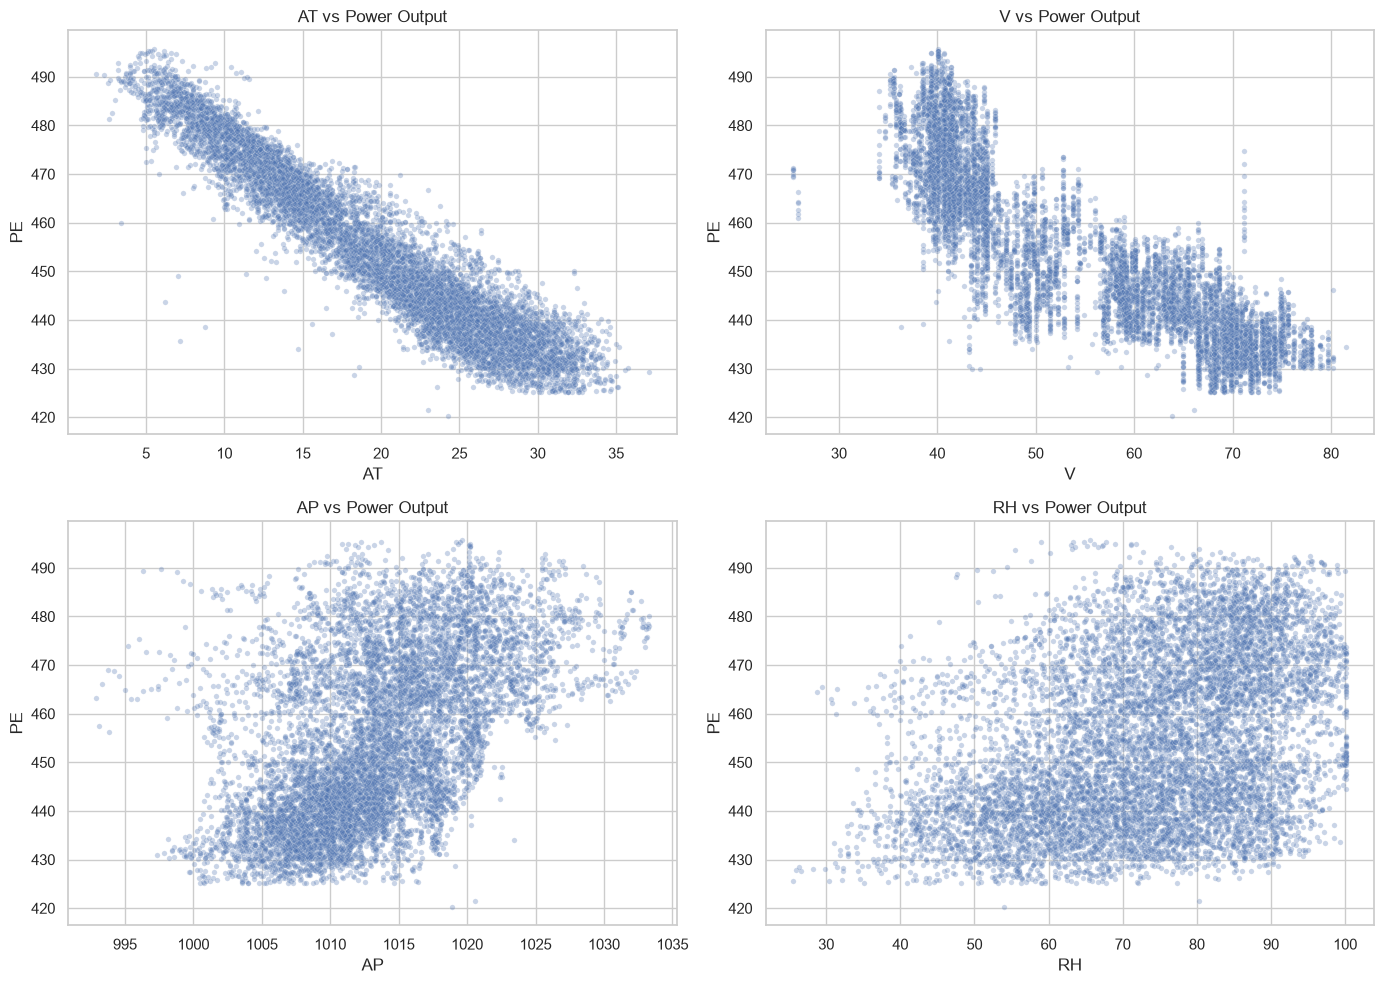

In [9]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="PE",
        alpha=0.3,
        s=15,
        ax=ax
    )
    ax.set_title(f"{feature} vs Power Output")

plt.tight_layout()
plt.show()


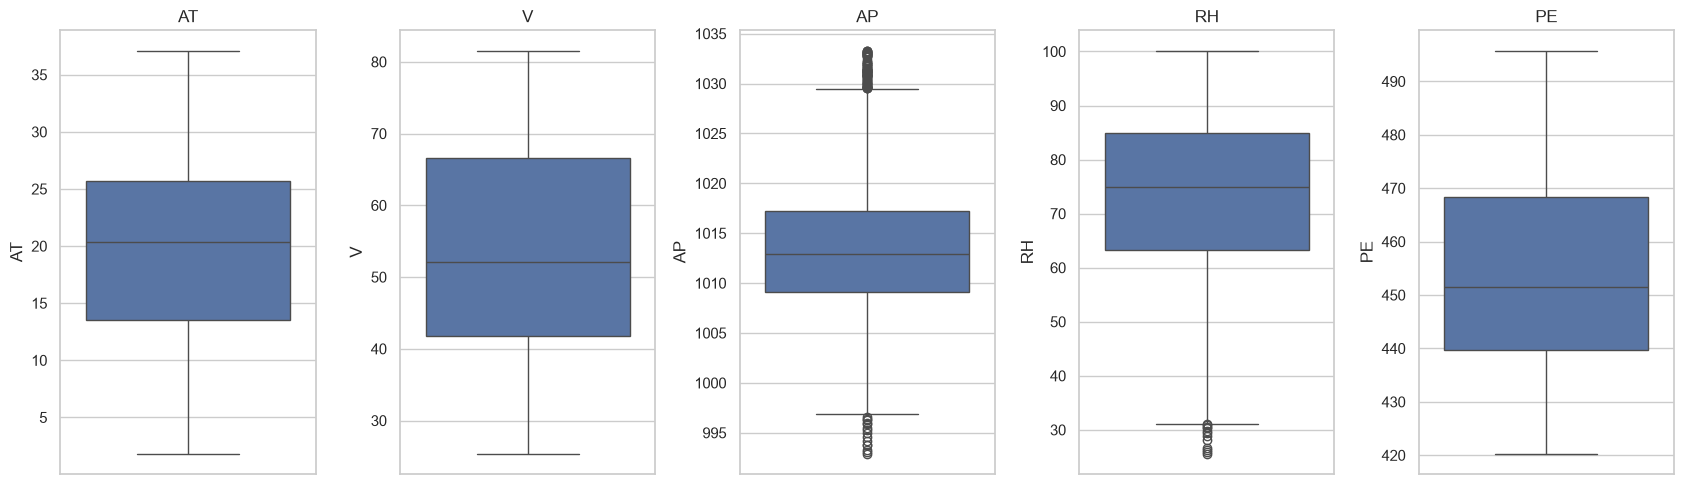

AT: 0 potential outliers
V: 0 potential outliers
AP: 88 potential outliers
RH: 12 potential outliers
PE: 0 potential outliers


In [10]:

fig, axes = plt.subplots(1, 5, figsize=(17, 5))

for ax, col in zip(axes, features + [target]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

for col in features + [target]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {outliers} potential outliers")



# PowerYield ML — EDA Findings

## Dataset Overview
- Observations: 9,568
- Input features: AT, V, AP, RH
- Target: PE (Net Electrical Power Output, MW)

## Data Quality
- Missing values:
- Duplicate observations:
- Potential outliers:

## Statistical Findings
- Strongest correlation with PE:
- Feature distributions:
- Important relationships:

## Modeling Decisions
- Baseline: Linear Regression
- Candidate models: Ridge, Random Forest, XGBoost
- Evaluation: MAE, RMSE, R²
- Data split: 60% training, 20% validation, 20% testing
- Test set reserved for final evaluation



## EDA Findings and Modeling Decisions

### Dataset Quality
- Total observations: 9,568
- Numerical features: AT, V, AP, RH
- Target variable: PE (MW)
- Missing values: 0
- Duplicate observations: 41
- Unique observations after deduplication: 9,527

### Key Findings
1. Ambient Temperature (AT) has the strongest negative
   correlation with power output (r = -0.948).
2. Exhaust Vacuum (V) also has a strong negative
   correlation with power output (r = -0.870).
3. Ambient Pressure (AP) shows a moderate positive
   correlation (r = 0.518).
4. Relative Humidity (RH) has a weaker positive
   correlation (r = 0.390).
5. AT and V are strongly correlated (r = 0.844),
   suggesting potential multicollinearity.
6. Feature distributions are not uniformly normal,
   and some relationships may be nonlinear.

### Modeling Strategy
- Remove exact duplicate rows before splitting.
- Use a reproducible 60/20/20 train/validation/test split.
- Establish Linear Regression as the baseline.
- Compare Ridge, Random Forest and XGBoost.
- Evaluate using MAE, RMSE and R².
- Select and tune models using validation data only.
- Reserve the test set for final evaluation.
